[instructions & rubric](https://course.ccs.neu.edu/ds4400f26-higger/learn/puzzle_problems.html)

# Puzzle: Ghost on the Circuit

A dorm's electric bill is higher than usual, and building services wants to know why.
A power meter logs the average watts it draws each hour.
Additionally, all 150 devices on campus uses a smart-plug system which tells whether they were on (1) or off (0) each hour.
Our goal is to identify which of these devices were plugged in to the dorm.

We simulate one such dataset as: `circuit = GhostCircuit.sample(seed=0)` which gives 72 hours of smart-plug logs `circuit.x` (one row per hour, one column per device) and meter readings `circuit.y`.
Assume that each device draws the same power in every hour its on, though the power consumption is unique per device and unknown a priori.

Write `estimate(x, y)`, which returns the devices (column numbers of `x`) you believe are on the metered circuit.  Anything on a circuit whose name starts with an underscore (e.g. `circuit._on_circuit`) is the hidden truth: peeking at it is cheating.  

Summarize your approach and efficacy in the submitted ipynb file.  Give a TPR and FPR for detected devices on as you validate your method across many seeds.

For fun, post your `estimate` to the [leaderboard](https://matthigger.github.io/ml_puzzle/ghost_circuit/) with class code `ghost-p3yt-rjx8-36ue` (no effect on your grade).


{'right': 3, 'wrong': 5, 'missed': 5, 'exact': False}
20 circuits: 3.6 of 8 devices found, 6.9 wrongly named, exactly right 0% of the time


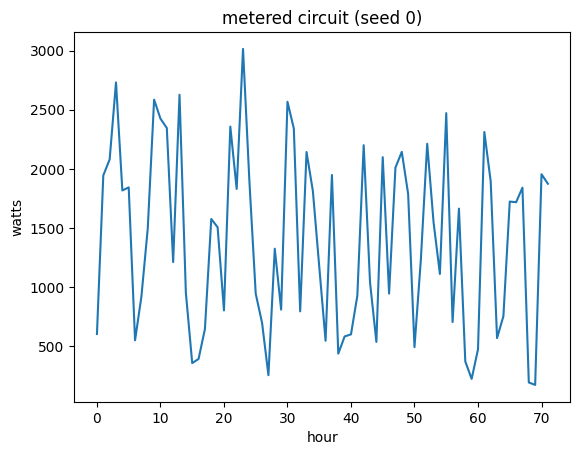

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from ghost_circuit import GhostCircuit, evaluate

circuit = GhostCircuit.sample(seed=0)
x, y = circuit.x, circuit.y
plt.plot(y)
plt.xlabel('hour')
plt.ylabel('watts')
plt.title('metered circuit (seed 0)')


def correlated(x, y):
    """ every device whose on / off pattern correlates with the meter """
    r = np.array([np.corrcoef(x[:, i], y)[0, 1] for i in range(x.shape[1])])
    return np.where(r > .2)[0]


print(circuit.score(correlated(x, y)))
evaluate(correlated);

## Executive summary

We built a method that predicts which devices are on the circuit. From each device's state (on/off) and the number of watts each hour, it predicts the number of devices that actually use the circuit's power. It has a mean true positive rate (TPR) of 87.75% and a mean false positive rate (FPR) of 5.92% across 100 different device spreads.

## Approach

We train a linear model with a lasso penalty. This encourages the model to zero out device power consumption for some devices, which effectively encourages the model to remove devices from the predicted circuit.


In [2]:
from sklearn.linear_model import Lasso

# Estimate function from ghost_circuit.py
# Returns a list of devices predicted to be on the circuit
def estimate_ex(x, y, lam):

    model = Lasso(alpha=lam / 2, fit_intercept=True, max_iter=100_000,
                  tol=1e-8)
    model.fit(x, y)
    return np.flatnonzero(model.coef_)

The number of devices off the predicted circuit scales with the parameter *lambda*. Lambda is decided by trial-and-error; we try many lambdas across 100 random circuits and measure the mean TPR and FPR.

First, run a wide sweep of lambdas from 0.01 to 25 to find the general range where good lambdas are.

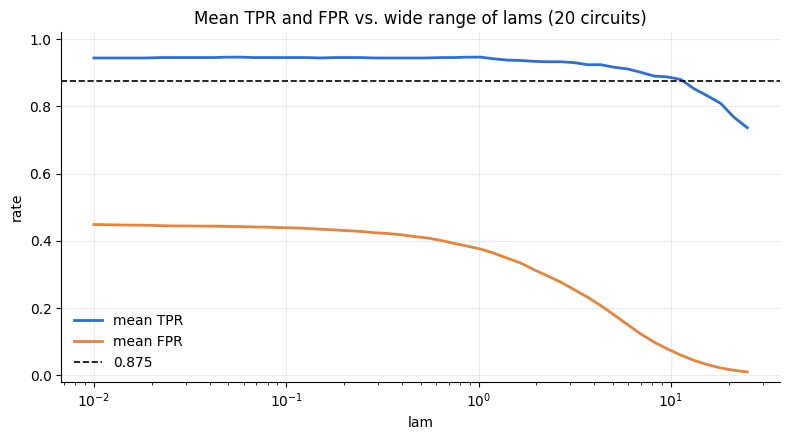

(<Figure size 800x450 with 1 Axes>,
 <Axes: title={'center': 'Mean TPR and FPR vs. wide range of lams (20 circuits)'}, xlabel='lam', ylabel='rate'>)

In [3]:
import warnings
import pandas as pd
from helper import sweep, plot

warnings.filterwarnings('ignore')

# Tests lambdas from 0.01-25 (log-spaced)
widesweep = sweep(np.logspace(np.log10(0.01), np.log10(25), 50))
plot(widesweep, 'Mean TPR and FPR vs. wide range of lams (20 circuits)', logx=True)

At a lambda of around 10, the FPR drastically dips while the TPR stays relatively constant. Thus, run a finer sweep of lambdas from 10 to 15 to find the best lambdas.

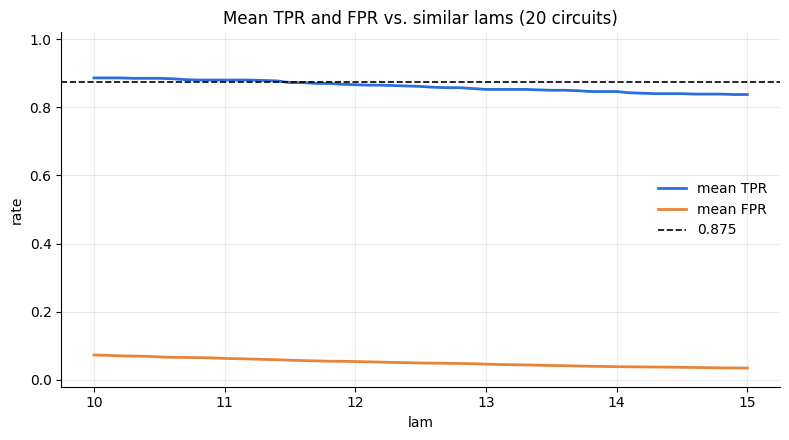

(<Figure size 800x450 with 1 Axes>,
 <Axes: title={'center': 'Mean TPR and FPR vs. similar lams (20 circuits)'}, xlabel='lam', ylabel='rate'>)

In [4]:
# Tests lambdas from 10-15
finesweep = sweep(np.linspace(10, 15, 51))
plot(finesweep, 'Mean TPR and FPR vs. similar lams (20 circuits)', logx=False)

The best lambda has a mean TPR of at least 87.5% while having the lowest mean FPR. On a circuit with 8 devices, the model will likely correctly predict 7 of them. It would be ideal to guess all 8 devices, but the FPR is too high. Note that this benchmark is decided by us based on the circuit setup given. Based on these criteria and on the 100 sample seeds, the best lambda is 11.4.

Also note that since the number of seeds is near-infinite, using a larger sample size of seeds will always result in a better lambda. The number of seeds we use is arbitrary.